# 07 · Real benzene solubility and a solid/liquid flash

The main course uses actual ThermoWeave models and real chemical components. See the [course index](../tutorials.md).

<a class="md-button" href="07_solubility_and_solid_liquid_flash.ipynb" download>Download notebook</a>


At 275 K, compute benzene's solubility in water using actual SAFT activities
and measured fusion properties. The pure-solid condition is
$\ln(x_B\gamma_B)=-\Delta h_{fus}/R(1/T-1/T_m)$ with ΔCp=0.
Then independently flash the feed with `ReducedHELD` and check the saturated
liquid. No synthetic fusion values or regular-solution liquid are used.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import SAFTgammaMie,FusionProperties
from thermoweave.equilibrium.sle import solubility
from thermoweave.equilibrium.reduced_held import ReducedChart,ReducedHELD,Solid
from _support import COMPONENTS,solid_gibbs,held_settings,check_flash,phase_table
names=['benzene','water'];T=275.
d=COMPONENTS['benzene'];print('Fusion source:',d['fusion_reference'],d['source_url'])
model=SAFTgammaMie.from_smiles({n:COMPONENTS[n]['smiles'] for n in names},pressure_Pa=101325.,report_assignment=False)
fusion=FusionProperties(d['melting_temperature_K'],d['enthalpy_of_fusion_J_mol'])
root=solubility(model,0,T,fusion)
print('Saturated liquid composition:',root.composition)
print('Solubility [benzene mole fraction]:',root.solubility,'; root residual:',root.residual)
chart=ReducedChart.build([0,0],[COMPONENTS[n]['molar_mass_g_mol'] for n in names])
solid=Solid('benzene(s)',[1.,0.],solid_gibbs(T))
result=ReducedHELD(model,T,chart,held_settings(),solids=[solid]).flash([.5,.5])
print(phase_table(result,names));print(check_flash(model,T,[.5,.5],result))
liquid=result.mole_fractions[result.phase_kinds.index('liquid')]
np.testing.assert_allclose(liquid,root.composition,atol=1e-8)

Fusion source: Oliver, Eaton and Huffman (1948), selected row in NIST Chemistry WebBook https://webbook.nist.gov/cgi/cbook.cgi?ID=C71432&Mask=4


Saturated liquid composition: [2.23810507e-04 9.99776189e-01]
Solubility [benzene mole fraction]: 0.00022381050730463565 ; root residual: 1.5704701920860042e-08


[{'phase': 'liquid', 'mole_fraction_of_total': 0.5001119303030563, 'mass_fraction_of_total': 0.1875929878957369, 'x_benzene': 0.00022381050375732507, 'x_water': 0.9997761894962426}, {'phase': 'benzene(s)', 'mole_fraction_of_total': 0.49988806969694377, 'mass_fraction_of_total': 0.8124070121042631, 'x_benzene': 1.0, 'x_water': 0.0}]
{'species_balance_error_mol': 1.1102230246251565e-16, 'liquid_mu_error_over_RT': 0.0, 'solid_saturation_error_over_RT': np.float64(1.4747578158669228e-12), 'gibbs_reconstruction_error_over_RT': np.float64(1.7617851622020453e-14), 'phase_mole_fractions': [0.5001119303030563, 0.49988806969694377], 'phase_mass_fractions': [0.1875929878957369, 0.8124070121042631]}


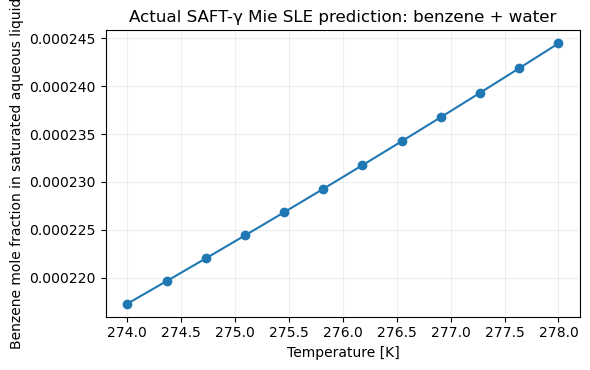

In [2]:
Ts=np.linspace(274.,278.,12)
x=[solubility(model,0,float(t),fusion).solubility for t in Ts]
fig,ax=plt.subplots(figsize=(6,3.8));ax.plot(Ts,x,'o-')
ax.set(xlabel='Temperature [K]',ylabel='Benzene mole fraction in saturated aqueous liquid',
       title='Actual SAFT-γ Mie SLE prediction: benzene + water')
ax.grid(alpha=.2);fig.tight_layout();plt.show()

This temperature range stays below the binary three-phase transition
computed in notebook 10 and above water's melting point. A solubility root by
itself does not select all competing phases; notebook 10 shows where a second
liquid becomes stable and notebook 11 computes actual ternary SLLE.